# 08 – Vorhersage: Die Netze sehen die Testblöcke zum ersten Mal

**Ziel.** Die vier gelernten Netze auf die **Testausschnitte** anwenden. Für jeden Testausschnitt entsteht eine Karte: Pixel für Pixel "Parkfläche gemeldet" oder nicht.

**Warum.** Die Testblöcke wurden in Notebook 02 festgelegt und seither weder zum Lernen noch zum Einstellen benutzt. Erst hier, nachdem Netz, Epoche und Schwelle feststehen, werden ihre Bilder gelesen. So zeigt das Ergebnis, was die Methode auf **neuen** Stellen leistet (`01b`, 8.1 K6).

**In diesem Notebook wird nichts mehr eingestellt.** Es wendet nur an, was Notebook 07 gespeichert hat. Die Lösung der Testausschnitte wird hier nicht angesehen; der Vergleich folgt in den Notebooks 09 und 10.

**Eingaben:** `ergebnisse/modelle/` und `ergebnisse/schwellen.json` (Notebook 07), `aufteilung.csv` (Notebook 02), die Luftbilder beider Jahre.
**Ausgaben:** `ergebnisse/masken/{Lauf}/{Ausschnitt}.npz` (gemeldete Parkfläche je Testausschnitt), Abbildung `08_vorhersage.png`.

In [1]:
import json                        # Einstellungen und Schwellen lesen
import shutil                      # alte Masken löschen
from pathlib import Path           # Pfade zusammensetzen

ROOT = Path.cwd().parent                             # Projektordner (eine Ebene über notebooks/)
ROH = ROOT / "daten" / "roh"                         # Rohdaten (werden nie verändert)
VERARB = ROOT / "daten" / "verarbeitet"              # abgeleitete Daten
ERG = ROOT / "ergebnisse"                            # Ergebnisse
ABB = ERG / "abbildungen"                            # Abbildungen
HAND = ROOT / "daten" / "ground_truth" / "ground_truth_hand.json"   # nur für die Zahl der DAV-Felder je Ausschnitt (Beispielwahl)

EINST = json.loads((ROOT / "einstellungen.json").read_text(encoding="utf-8"))   # Einstellungen früherer Notebooks
KACHEL_PX, VERSUCHE, AUFLOESUNGEN_CM = EINST["KACHEL_PX"], EINST["VERSUCHE"], EINST["AUFLOESUNGEN_CM"]
SCHWELLEN = json.loads((ERG / "schwellen.json").read_text(encoding="utf-8"))    # Schwelle je Lauf (Notebook 07, eingefroren)
print("Schwellen aus Notebook 07:", {lauf: werte["schwelle"] for lauf, werte in SCHWELLEN.items()})

import numpy as np                 # Pixelraster
import pandas as pd                # Tabellen
import matplotlib.pyplot as plt    # Abbildungen
import rasterio                    # Luftbilder lesen
from rasterio.merge import merge   # Ausschnitt aus mehreren Bilddateien zusammensetzen
import torch                       # neuronale Netze
from netz import GERAET, MITTEL, STREUUNG, lade_modell   # Bauplan und Laden des Netzes (Datei netz.py)

Schwellen aus Notebook 07: {'A_10cm': 0.4, 'B_10cm': 0.5, 'A_5cm': 0.45, 'B_5cm': 0.35}


**Einstellungen dieses Schritts.**

| Einstellung | Wert | Warum |
| --- | --- | --- |
| `RAND_PX` | 256 Pixel | Um jeden Testausschnitt wird ein Rand mitgelesen, damit das Netz auch an den Kanten Umgebung sieht |
| `SCHRITT_PX` | 256 Pixel | Die Fenster von 512 Pixeln überlappen sich zur Hälfte |
| `KACHEL_M` | 51,2 m | Seitenlänge eines Ausschnitts |

In [2]:
RAND_PX = 256
SCHRITT_PX = 256
KACHEL_M = 51.2

## 1. Die Testausschnitte und ihre Bilder

**Schritt 1: Testausschnitte lesen.** Nur die Gruppe `testen` aus Notebook 02.

Vorher: 691 Ausschnitte → nachher: die Testausschnitte.

In [3]:
aufteilung = pd.read_csv(VERARB / "aufteilung.csv")
test = aufteilung[aufteilung.gruppe == "testen"].reset_index(drop=True)      # Maske und Auswahl: nur Testausschnitte
print(f"Vorher: {len(aufteilung)} Ausschnitte → nachher: {len(test)} Testausschnitte in {test.block.nunique()} Blöcken")

Vorher: 691 Ausschnitte → nachher: 137 Testausschnitte in 15 Blöcken


**Schritt 2: das Bild eines Testausschnitts mit Rand lesen.** Dieselben zwei Funktionen wie in Notebook 05: `lies_bild` setzt den Rahmen aus den Bilddateien zusammen (5 cm), `halbiere` mittelt je 2 × 2 Pixel (10 cm).

Der Rand ist in Pixeln festgelegt (256). In Metern ist er bei 10 cm doppelt so breit wie bei 5 cm: Jedes Netz bekommt gleich viele Pixel Umgebung.

In [4]:
QUELLEN = {}                                                         # geöffnete Bilddateien je Versuch
for versuch, angaben in VERSUCHE.items():
    QUELLEN[versuch] = [rasterio.open(pfad) for pfad in sorted((ROH / "orthofoto" / angaben["ordner"]).glob("*.tif"))]

def lies_bild(versuch, rahmen):
    # Liest den Rahmen (links, unten, rechts, oben) bei 5 cm: Rot, Grün, Blau als Zahlen 0 bis 255 (wie Notebook 05)
    bild, _ = merge(QUELLEN[versuch], bounds=rahmen, res=0.05, indexes=[1, 2, 3])
    return bild

In [5]:
def halbiere(bild):
    # Mittelt je 2 × 2 Pixel: aus 5 cm wird 10 cm (wie Notebook 05)
    kanaele, hoehe, breite = bild.shape
    bloecke = bild.reshape(kanaele, hoehe // 2, 2, breite // 2, 2).astype("uint16")
    return ((bloecke.sum(axis=(2, 4)) + 2) // 4).astype("uint8")

In [6]:
def bild_mit_rand(versuch, ausschnitt, aufloesung_cm):
    # Bild eines Ausschnitts samt Rand von 256 Pixeln, in der verlangten Auflösung
    rand_m = RAND_PX * aufloesung_cm / 100                           # 12,8 m bei 5 cm, 25,6 m bei 10 cm
    links, unten = ausschnitt.i * KACHEL_M - rand_m, ausschnitt.j * KACHEL_M - rand_m
    bild = lies_bild(versuch, (links, unten, links + KACHEL_M + 2 * rand_m, unten + KACHEL_M + 2 * rand_m))
    return bild if aufloesung_cm == 5 else halbiere(bild)

dav_je_ausschnitt = pd.DataFrame(json.loads(HAND.read_text(encoding="utf-8"))["kacheln"]).set_index("id").dav_felder   # Zahl der DAV-Felder
beispiel = test.loc[test.kachel.map(dav_je_ausschnitt).idxmax()]     # Testausschnitt mit den meisten DAV-Feldern
bild = bild_mit_rand("A", beispiel, 5)
print("Beispiel:", beispiel.kachel, "| Bild mit Rand:", bild.shape)

Beispiel: k_52407_24354 | Bild mit Rand: (3, 1536, 1536)


## 2. Die Vorhersage mit überlappenden Fenstern

**Worum es geht.** Das Netz sieht jeweils 512 × 512 Pixel. Am Rand eines Fensters fehlt ihm die Umgebung, dort ist es unsicherer. Darum fahren wir das Bild mit Fenstern ab, die sich zur Hälfte überlappen, und **mitteln** für jeden Pixel die Antworten aller Fenster, die ihn enthalten (`01b`, 7.5).

**Was gemittelt wird.** Das Netz gibt je Pixel zwei Rohwerte. Ihr Unterschied $d$ = Parkfläche − keine ist positiv, wenn das Netz eher Parkfläche sieht.

**Schritt 1: die Funktion.** `summe` sammelt die Werte, `anzahl` zählt, wie viele Fenster einen Pixel gesehen haben. Am Schluss: Mittel = Summe ÷ Anzahl.

In [7]:
@torch.no_grad()                                                     # nur anwenden, nicht lernen
def unterschied_karte(modell, bild):
    # Mittlerer Unterschied der Rohwerte (Parkfläche − keine) je Pixel, über alle Fenster, die den Pixel enthalten
    _, hoehe, breite = bild.shape
    summe = np.zeros((hoehe, breite), np.float32)
    anzahl = np.zeros((hoehe, breite), np.float32)
    normiert = (torch.from_numpy(bild).float() / 255.0 - MITTEL) / STREUUNG      # wie beim Lernen (Notebook 07)
    for z in range(0, hoehe - KACHEL_PX + 1, SCHRITT_PX):            # Fenster von oben nach unten
        for s in range(0, breite - KACHEL_PX + 1, SCHRITT_PX):       # und von links nach rechts
            fenster = normiert[:, z:z + KACHEL_PX, s:s + KACHEL_PX].unsqueeze(0).to(GERAET)
            with torch.autocast(GERAET, dtype=torch.float16, enabled=GERAET == "cuda"):
                rohwerte = modell(fenster)[0].float()                # [2, 512, 512]
            summe[z:z + KACHEL_PX, s:s + KACHEL_PX] += (rohwerte[1] - rohwerte[0]).cpu().numpy()
            anzahl[z:z + KACHEL_PX, s:s + KACHEL_PX] += 1
    return summe / anzahl

**Schritt 2: von der Sicherheit zur Meldung.** Notebook 07 hat je Lauf eine Schwelle $\tau$ für die **Sicherheit** $p$ gewählt (eine Zahl zwischen 0 und 1). Sicherheit und Unterschied hängen fest zusammen: $p > \tau$ gilt genau dann, wenn $d > \ln\big(\tau / (1 - \tau)\big)$. Bei $\tau = 0{,}5$ ist die Grenze 0.

Danach wird der Rand abgeschnitten: Es bleibt genau der Ausschnitt.

**Ein Unterschied zu Notebook 07.** Die Schwelle wurde dort an einzelnen Kacheln gewählt, ohne überlappende Fenster. Hier wird über mehrere Fenster gemittelt. Die Meldung kann darum leicht anders ausfallen als auf der Validierung; die Schwelle bleibt trotzdem, wie sie festgelegt wurde.

In [8]:
def meldung(modell, bild, schwelle):
    # Karte "Parkfläche gemeldet" (True/False) für den Ausschnitt ohne Rand
    unterschied = unterschied_karte(modell, bild)
    grenze = np.log(schwelle / (1 - schwelle))                       # Schwelle der Sicherheit, umgerechnet auf den Unterschied
    return unterschied[RAND_PX:-RAND_PX, RAND_PX:-RAND_PX] > grenze, unterschied[RAND_PX:-RAND_PX, RAND_PX:-RAND_PX]

modell = lade_modell("A_5cm")
gemeldet, unterschied = meldung(modell, bild, SCHWELLEN["A_5cm"]["schwelle"])
print("Beispiel", beispiel.kachel, "| Karte:", gemeldet.shape, f"| gemeldete Parkfläche: {gemeldet.mean():.1%} der Pixel")

Beispiel k_52407_24354 | Karte: (1024, 1024) | gemeldete Parkfläche: 13.8% der Pixel


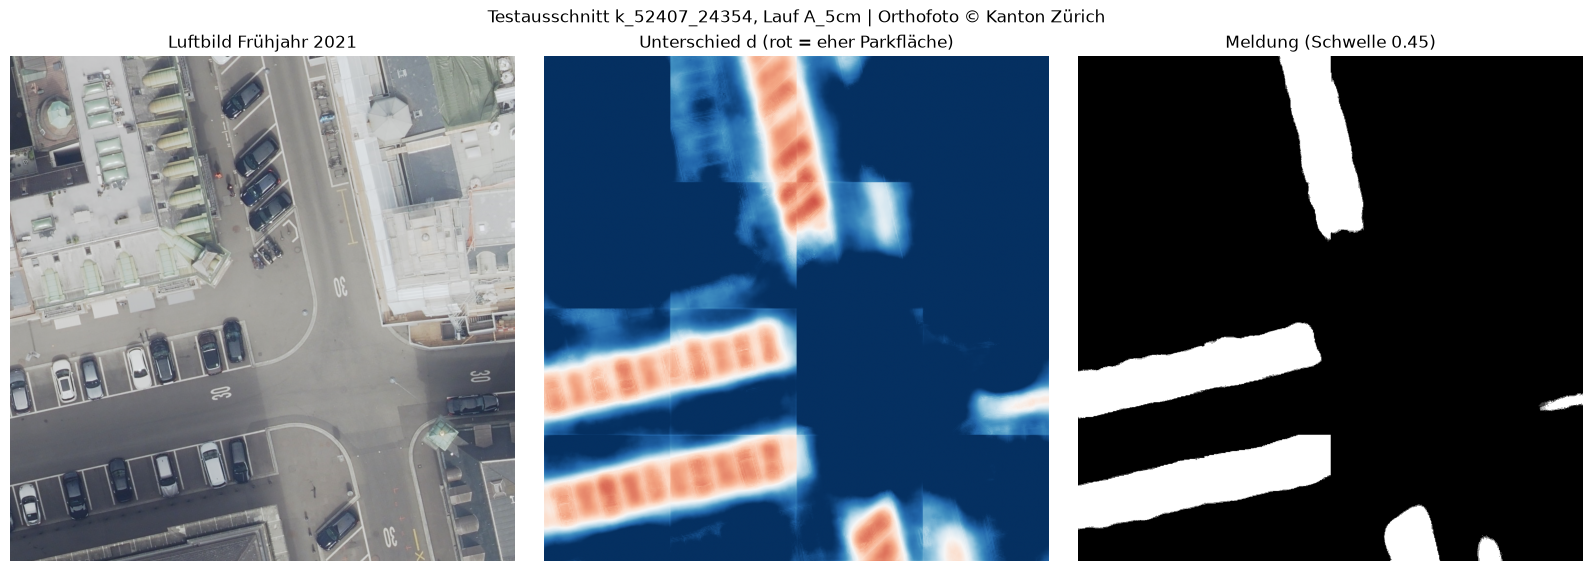

In [9]:
# Abbildung: Luftbild, Unterschied der Rohwerte und Meldung für den Beispiel-Ausschnitt (Lauf A_5cm)
fig, achsen = plt.subplots(1, 3, figsize=(16, 5.6), layout="constrained")
achsen[0].imshow(bild[:, RAND_PX:-RAND_PX, RAND_PX:-RAND_PX].transpose(1, 2, 0))
achsen[0].set_title("Luftbild Frühjahr 2021")
achsen[1].imshow(unterschied, cmap="RdBu_r", vmin=-8, vmax=8)
achsen[1].set_title("Unterschied d (rot = eher Parkfläche)")
achsen[2].imshow(gemeldet, cmap="gray")
achsen[2].set_title(f"Meldung (Schwelle {SCHWELLEN['A_5cm']['schwelle']})")
for ax in achsen:
    ax.set_axis_off()
fig.suptitle(f"Testausschnitt {beispiel.kachel}, Lauf A_5cm | Orthofoto © Kanton Zürich")
fig.savefig(ABB / "08_vorhersage.png", dpi=100, bbox_inches="tight")
plt.show()
del modell
torch.cuda.empty_cache()                                             # Grafikspeicher freigeben

**Was die Abbildung zeigt.** Links, was das Netz sieht. In der Mitte, wie sicher es ist (kräftiges Rot: sicher Parkfläche; kräftiges Blau: sicher keine). Rechts die Meldung, wie sie gezählt wird. Ob sie stimmt, zeigt erst der Vergleich mit der Lösung in Notebook 10.

## 3. Alle Testausschnitte, alle vier Läufe

Dieselben Schritte für jeden Testausschnitt und jeden Lauf. Gespeichert wird je Ausschnitt die Karte der Meldung.

Vorher: Testausschnitte → nachher: je Lauf eine Karte je Testausschnitt.

In [10]:
shutil.rmtree(ERG / "masken", ignore_errors=True)                    # alte Masken entfernen
zeilen = []
for versuch in VERSUCHE:
    for aufloesung_cm in AUFLOESUNGEN_CM:
        lauf = f"{versuch}_{aufloesung_cm}cm"
        (ERG / "masken" / lauf).mkdir(parents=True)
        modell = lade_modell(lauf)                                   # bester Stand dieses Laufs (Notebook 07)
        for ausschnitt in test.itertuples():
            gemeldet, _ = meldung(modell, bild_mit_rand(versuch, ausschnitt, aufloesung_cm), SCHWELLEN[lauf]["schwelle"])
            np.savez_compressed(ERG / "masken" / lauf / f"{ausschnitt.kachel}.npz", gemeldet=gemeldet)
            zeilen.append(dict(lauf=lauf, kachel=ausschnitt.kachel, anteil_gemeldet=float(gemeldet.mean())))
        del modell
        torch.cuda.empty_cache()                                     # Grafikspeicher freigeben
        print(lauf, "fertig")
uebersicht = pd.DataFrame(zeilen)
uebersicht.groupby("lauf").anteil_gemeldet.agg(ausschnitte="size", mittlerer_anteil_gemeldet="mean").round(4)

A_5cm fertig


A_10cm fertig


B_5cm fertig


B_10cm fertig


,ausschnitte,mittlerer_anteil_gemeldet
lauf,,
A_10cm,137,0.0212
A_5cm,137,0.0223
B_10cm,137,0.0147
B_5cm,137,0.0168


## Was wir gesehen haben

- Für jeden der vier Läufe liegt je Testausschnitt eine Karte der gemeldeten Parkfläche vor.
- Der mittlere Anteil gemeldeter Pixel steht in der Tabelle. Zum Vergleich: In den Lernkacheln ist rund 1 bis 1,5 % der Pixel Parkfläche (Notebook 05).

## Wie es weitergeht

Notebook 09 macht aus den gemeldeten Flächen Anzahlen und stellt sie neben die Ground Truth und die amtlichen Daten.